# Preprocessing the C-MAPSS FD001 dataset

**Notebook 01 of the thesis project "Explainable Graph Neural Networks for Remaining Useful Life prediction".**

---

## What this notebook is for

This notebook turns the raw NASA C-MAPSS text files into arrays that a graph neural network can be trained on, and explains every decision made along the way.

It is written to be read as well as run. Each step has three parts:

1. **What** the step does.
2. **Why** it is necessary.
3. **A check** confirming it did what was intended.

## Who it is written for

A researcher who knows some Python and some machine learning, but who has not worked with this dataset or with graph neural networks before. Every technical term is defined the first time it appears, with a reference to a source where it is defined properly.

## What this notebook does *not* do

It does not train a model. Preprocessing is a separate stage on purpose: it has to be right before any model result means anything, and it is much easier to check on its own.

## A note on honesty

This project re-implements a published paper (Wen et al., 2026) that does not describe every detail of its own method. Wherever a choice had to be made here rather than read from the paper, this notebook says so and marks it with an assumption number such as **A-03**. The full list, with justifications, is in `docs/ASSUMPTIONS.md`.

---

## The whole notebook in one list

Every step below takes the output of the step before it. Read this list first;
the rest of the notebook is these eight lines, expanded.

| # | Step | What goes in | What comes out |
|---|------|--------------|----------------|
| 1 | **Load** the three text files | `train_FD001.txt`, `test_FD001.txt`, `RUL_FD001.txt` | one table, 20 631 rows, with a "cycles of life left" number attached to every row |
| 2 | **Diagnose** the sensors | that table | a report saying which of the 21 sensors never change |
| 3 | **Select** 14 sensors | 21 sensor columns | the 14 the paper keeps, in the order its graph expects |
| 4 | **Cap** the labels at 125 | labels running up to 361 | labels running up to 125, flat while the engine is healthy |
| 5 | **Smooth** the readings | jagged sensor traces | the same traces with the measurement noise damped |
| 6 | **Split** off 20 engines | 100 training engines | 80 to learn from, 20 held back to check on |
| 7 | **Rescale** every sensor | numbers from 0.03 to 1400 | numbers between 0 and 1 |
| 8 | **Cut** into windows | one long history per engine | 17 731 fixed-size examples of shape 14 sensors x 30 cycles |

The result is an array of shape `(17731, 14, 30)` and a 14 x 14 table saying
which sensors are connected to which. Those two things are what a graph neural
network needs, and producing them correctly is the entire job of this notebook.

## Where the code actually is

The instructions that do the work are **not** in this notebook. They are in a
folder of Python files at `src/thesis_gnn_rul_xai/`, and this notebook calls
them.

For example, step 5 is one line here:

```python
train_smoothed = apply_ewma(train_frame, sensor_columns, alpha=0.5)
```

but `apply_ewma` is about 170 lines in `src/thesis_gnn_rul_xai/data/smoothing.py`,
and eight automated tests check it.

The reason for that split: a notebook can be run out of order. You can execute
cell 20 before cell 5, get a wrong answer that looks fine, and never be told.
Code kept in separate files cannot be run out of order and can be tested
automatically. So the files hold the computation, and this notebook shows what
that computation does and why. Section 9 of `README.md` explains the folder
layout in full.

## 1. Background

### The problem

A jet engine wears out gradually. **Remaining Useful Life (RUL)** is the number of flight cycles an engine will still run before it fails. One *flight cycle* is one complete take-off, flight and landing; it is the only unit of time in this project. Predicting RUL from sensor readings lets an airline plan maintenance before a failure happens.

### The dataset

**C-MAPSS** stands for *Commercial Modular Aero-Propulsion System Simulation*, a NASA program that simulates a large turbofan engine. NASA used it to build a public benchmark in which simulated engines run until failure while 21 sensors record the engine state once per cycle (Saxena et al., 2008).

The benchmark has four sub-datasets. This notebook uses **FD001**, the simplest: one operating condition and one fault mode, 100 training engines and 100 test engines. Starting with the simplest case is deliberate — a pipeline that is wrong here would be wrong everywhere, and the mistake is far easier to find.

| | FD001 | FD002 | FD003 | FD004 |
|---|---|---|---|---|
| Operating conditions | 1 | 6 | 1 | 6 |
| Fault modes | 1 | 1 | 2 | 2 |
| Training engines | 100 | 260 | 100 | 249 |
| Test engines | 100 | 259 | 100 | 248 |

### Training data and test data are shaped differently

This is the single most important thing to understand about C-MAPSS:

- **Training engines run to failure.** The last recorded row for an engine *is* the failure, so the remaining life at that row is zero by definition. No label file is needed.
- **Test engines stop early.** Recording ends at some point before failure. A separate file, `RUL_FD001.txt`, gives one number per test engine: how much life was left at its last recorded row.

Everything about how labels are computed follows from this difference.

### Why a *graph*

A turbofan is a chain of components. Air enters the fan, is compressed, is burned with fuel, and drives the turbines on the way out. A change in one part shows up in the sensors of the next. Treating the sensors as unrelated numbers throws that structure away.

A **graph** is a set of points, called **nodes**, with connections between them, called **edges**. Here each sensor is a node, and an edge means "these two measurements are physically related". A **graph neural network** uses those edges to decide which sensors may exchange information (Kipf & Welling, 2017; Corso et al., 2024).

## 2. Setup

The cell below imports the functions used throughout. Each import line is a
path through the project's folders. Reading one of them:

```python
from thesis_gnn_rul_xai.data.smoothing import apply_ewma
```

means: in the folder `thesis_gnn_rul_xai`, open the folder `data`, open the
file `smoothing.py`, and take the function `apply_ewma` defined inside it.
Those folders are at `src/thesis_gnn_rul_xai/`, and `sys.path.insert` on the
line below tells Python where to find them when the project has not been
installed with `pip install -e .`.

`help(apply_ewma)` in any empty cell prints one line saying what a function
does. The full explanation — why the step is done this way, what the paper
says about it, and what each argument means — is in the `README.md` file in
the same folder as the code, here `src/thesis_gnn_rul_xai/data/README.md`.

In [1]:
from __future__ import annotations

import logging
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Make the package importable when the notebook is opened directly from a
# clone that has not been installed with `pip install -e .`.
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from thesis_gnn_rul_xai.config import PreprocessingConfig
from thesis_gnn_rul_xai.data.labeling import apply_piecewise_rul
from thesis_gnn_rul_xai.data.loading import load_subset
from thesis_gnn_rul_xai.data.normalization import (
    CONDITION_COL,
    OperatingConditionEncoder,
    SensorNormalizer,
)
from thesis_gnn_rul_xai.data.pipeline import run_preprocessing
from thesis_gnn_rul_xai.data.sensors import (
    PAPER_EXCLUDED_SYMBOLS,
    PAPER_SENSOR_COLUMNS,
    PAPER_SENSOR_SYMBOLS,
    SENSORS,
    column_to_symbol,
    detect_uninformative_sensors,
)
from thesis_gnn_rul_xai.data.smoothing import apply_ewma
from thesis_gnn_rul_xai.data.windowing import (
    make_last_windows,
    make_windows,
    split_units_by_id,
)
from thesis_gnn_rul_xai.graph.adjacency import (
    adjacency_report,
    build_correlation_adjacency,
    build_physics_adjacency,
    normalize_adjacency,
)
from thesis_gnn_rul_xai.utils.logging_setup import configure_logging
from thesis_gnn_rul_xai.utils.seeding import set_global_seed

configure_logging(logging.INFO)
set_global_seed(42)

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "figure.figsize": (10, 4), "font.size": 9})

print(f"Project root: {PROJECT_ROOT}")
print(f"Python       : {sys.version.split()[0]}")
print(f"NumPy        : {np.__version__}")
print(f"pandas       : {pd.__version__}")

Project root: D:\Main\University\Thesis\Code\Thesis GNN RUL XAI
Python       : 3.11.9
NumPy        : 2.4.6
pandas       : 3.0.3


### The configuration object

Every setting that controls the pipeline is collected in one object rather than scattered through the code. Saving that object next to a result records exactly which settings produced it.

Settings marked **ASSUMPTION** below are *not* stated in the paper. They are choices made here, and each is explained in `docs/ASSUMPTIONS.md`.

In [2]:
config = PreprocessingConfig(
    subset="FD001",
    window_size=30,        # From the paper, Table 6.
    window_stride=1,       # A-05: not stated in the paper.
    rul_max=125,           # A-01: the paper never prints this value.
    clip_test_labels=True, # A-02: forced by the sigmoid output layer.
    normalization="minmax_per_condition",  # A-03: the paper is silent.
    smoothing_alpha=0.5,   # A-04: the paper's sentence is self-contradictory.
    node_feature_mode="window",  # A-07: no LSTM, so nodes carry the window.
    validation_fraction=0.2,     # A-06: the paper has no validation split.
    seed=42,
)

for field_name, value in config.to_dict().items():
    if field_name != "notes":
        print(f"  {field_name:22s} {value}")

  subset                 FD001
  window_size            30
  window_stride          1
  rul_max                125
  clip_test_labels       True
  normalization          minmax_per_condition
  smoothing_alpha        0.5
  node_feature_mode      window
  validation_fraction    0.2
  seed                   42


## 3. Locating the data

This notebook runs on the real NASA measurements and nothing else. There is no stand-in dataset: a pipeline that appears to work on invented signals tells you nothing about whether it works on engines.

If the FD001 files are not in `data/raw/`, the next cell stops with a link to the download. Section 5 of `README.md` has the same instructions, and `python scripts/prepare_data.py --check` gives the same report from the command line.

In [3]:
data_dir = PROJECT_ROOT / "data" / "raw"
required = [f"train_{config.subset}.txt", f"test_{config.subset}.txt", f"RUL_{config.subset}.txt"]
missing = [name for name in required if not (data_dir / name).is_file()]

if missing:
    raise FileNotFoundError(
        f"The {config.subset} files are not in {data_dir}: {missing}.\n\n"
        "This notebook runs on the real NASA measurements and nothing else. "
        "Download the 'Turbofan Engine Degradation Simulation Data Set' from\n\n"
        "    https://www.nasa.gov/intelligent-systems-division/discovery-and-systems-health/pcoe/pcoe-data-set-repository/\n\n"
        f"and put the three {config.subset} files into {data_dir}. If you keep the "
        "dataset elsewhere, set data_dir to that folder instead."
    )

print(f"Using the real NASA C-MAPSS files for {config.subset}.")
print(f"Data directory: {data_dir}")

Using the real NASA C-MAPSS files for FD001.
Data directory: D:\Main\University\Thesis\Code\Thesis GNN RUL XAI\data\raw


## 4. Step 1 — Load the raw files

### What a raw file looks like

Each row describes one engine at one flight cycle, in 26 columns:

| Column | Meaning |
|---|---|
| 1 | Engine number (an identifier, not a measurement) |
| 2 | Cycle number, counted from when the engine was new |
| 3-5 | Three operational settings: altitude, Mach number, throttle angle |
| 6-26 | Twenty-one sensor readings |

There is no header row, and the columns are separated by spaces.

### How labels are computed

For **training** engines, which run to failure:

$$\text{RUL}(t) = t_{\text{last}} - t$$

For **test** engines, which stop early, the label file supplies the missing piece:

$$\text{RUL}(t) = (t_{\text{last}} - t) + \text{RUL}_{\text{official}}$$

Worked example: an engine's last recorded cycle is 150 and the label file says 47 cycles remained at that moment. At cycle 130 the engine still had $(150 - 130) + 47 = 67$ cycles left.

In [4]:
data = load_subset(config.subset, data_dir=data_dir)
print()
display(data.summary())

12:29:25 | INFO    | thesis_gnn_rul_xai.data.loading | Loading FD001 from D:\Main\University\Thesis\Code\Thesis GNN RUL XAI\data\raw


12:29:25 | INFO    | thesis_gnn_rul_xai.data.loading | FD001 matches the published shape of the official release.


12:29:25 | INFO    | thesis_gnn_rul_xai.data.loading | Loaded FD001: 20631 training rows over 100 engines, 13096 test rows over 100 engines.


,rows,engines,shortest_history,longest_history,median_history
split,,,,,
train,20631,100,128,362,199.0
test,13096,100,31,303,133.5


In [5]:
# The first rows of the first engine. Note that `rul` counts down by one each
# cycle and that the operational settings barely move: FD001 has a single
# operating condition.
columns_to_show = ["unit", "cycle", "op_setting_1", "op_setting_2", "op_setting_3",
                   "sensor_2", "sensor_3", "sensor_4", "rul"]
display(data.train[columns_to_show].head(5))
print("...")
display(data.train[data.train["unit"] == 1][columns_to_show].tail(3))

,unit,cycle,op_setting_1,op_setting_2,op_setting_3,sensor_2,sensor_3,sensor_4,rul
0,1,1,-0.0007,-0.0004,100.0,641.82,1589.70,1400.60,191
1,1,2,0.0019,-0.0003,100.0,642.15,1591.82,1403.14,190
2,1,3,-0.0043,0.0003,100.0,642.35,1587.99,1404.20,189
3,1,4,0.0007,0.0000,100.0,642.35,1582.79,1401.87,188
4,1,5,-0.0019,-0.0002,100.0,642.37,1582.85,1406.22,187


...


,unit,cycle,op_setting_1,op_setting_2,op_setting_3,sensor_2,sensor_3,sensor_4,rul
189,1,190,-0.0027,0.0001,100.0,643.64,1599.22,1425.95,2
190,1,191,-0.0000,-0.0004,100.0,643.34,1602.36,1425.77,1
191,1,192,0.0009,-0.0000,100.0,643.54,1601.41,1427.20,0


**Check.** The final label of every training engine must be exactly zero: the last recorded cycle *is* the failure. And for every test engine, the label computed at its last recorded cycle must equal the number in the official label file.

In [6]:
final_training_labels = data.train.groupby("unit")["rul"].last()
assert (final_training_labels == 0).all(), "A training engine does not end at RUL = 0."
print(f"OK  All {len(final_training_labels)} training engines end at RUL = 0.")

computed_last = data.test.groupby("unit")["rul"].last().sort_index()
official = data.test_rul.sort_index()
assert (computed_last.to_numpy() == official.to_numpy()).all(), "Test labels disagree."
print(f"OK  All {len(official)} test-engine labels match the official label file.")
print(f"    Official remaining life ranges from {official.min()} to {official.max()} cycles.")

OK  All 100 training engines end at RUL = 0.
OK  All 100 test-engine labels match the official label file.
    Official remaining life ranges from 7 to 145 cycles.


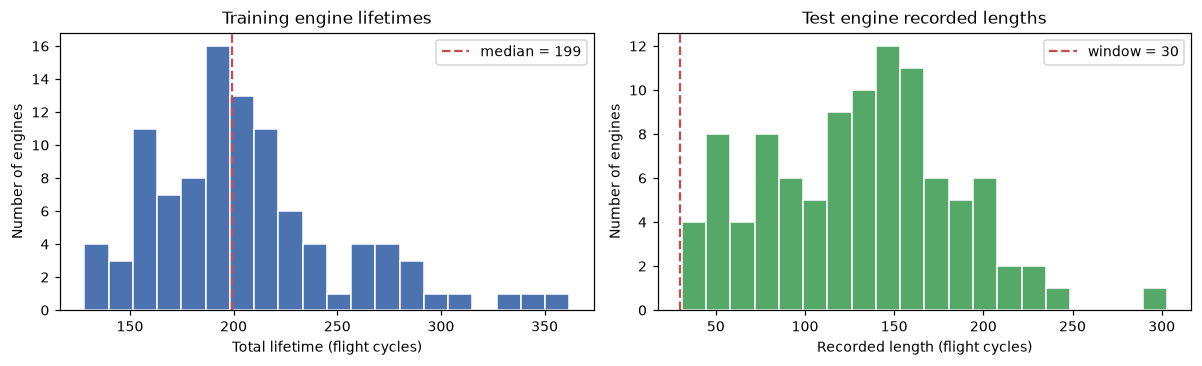

Shortest test history: 31 cycles.
Window size          : 30 cycles.
Every test engine is long enough for one full window.


In [7]:
# How long do engines live? The spread is wide, which is what makes the task
# non-trivial: age alone is a poor predictor of remaining life.
lifetimes = data.train.groupby("unit")["cycle"].max()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].hist(lifetimes, bins=20, color="#4C72B0", edgecolor="white")
axes[0].set_xlabel("Total lifetime (flight cycles)")
axes[0].set_ylabel("Number of engines")
axes[0].set_title("Training engine lifetimes")
axes[0].axvline(lifetimes.median(), color="#C44E52", linestyle="--",
                label=f"median = {lifetimes.median():.0f}")
axes[0].legend()

test_lengths = data.test.groupby("unit")["cycle"].max()
axes[1].hist(test_lengths, bins=20, color="#55A868", edgecolor="white")
axes[1].set_xlabel("Recorded length (flight cycles)")
axes[1].set_ylabel("Number of engines")
axes[1].set_title("Test engine recorded lengths")
axes[1].axvline(config.window_size, color="#C44E52", linestyle="--",
                label=f"window = {config.window_size}")
axes[1].legend()

fig.tight_layout()
plt.show()

print(f"Shortest test history: {test_lengths.min()} cycles.")
print(f"Window size          : {config.window_size} cycles.")
if test_lengths.min() < config.window_size:
    print("NOTE: at least one test engine is shorter than the window and will be padded.")
else:
    print("Every test engine is long enough for one full window.")

## 5. Step 2 — Which sensors carry information?

Some of the 21 sensors never change during an engine's entire life. A flat line
contains no information about degradation and cannot help any model.

Wen et al. (2026) keep 14 sensors and drop 7. The next cell checks that decision **against the data itself** rather than taking it on trust. Any disagreement is a finding worth reporting, not something to hide.

### What the check finds on the real FD001 data

Two things, both worth a sentence in the thesis:

- **Exactly six sensors are perfectly constant**, and they are exactly the six the paper *names*. The seventh sensor missing from its adjacency matrix, `NRc`, is **not** constant — it takes over six thousand distinct values. It must have been dropped for another reason, most plausibly redundancy, since the corrected core speed is derived from the physical core speed `Nc`, which the paper keeps. The paper's sentence merges two different reasons for exclusion (**assumption A-10**).
- **`P15` is kept by the paper but takes only two distinct values** in the entire training set. It cannot represent gradual wear. It is kept here anyway, because the adjacency matrix is defined over the paper's fixed 14 sensors and removing a node would change the graph. The pipeline reports it rather than silently correcting it (**finding F-01**).

The right test here is the *number of distinct values*, not the size of the range: `Nf` has a smaller relative range than `P15` but spreads it over 53 levels and is genuinely informative.

### A discrepancy in the paper

Section 3.2.2 of the paper says "seven sensors are removed" but then names only six: T2, P2, epr, farB, Nfdmd and PCNRdmd. Comparing the full sensor list in their Table 2 with the 14 sensors in their adjacency matrix in Table 3 shows the missing seventh is **NRc**, the corrected core speed. This project follows Table 3, because that is the list the model actually consumes (assumption **A-10**).

In [8]:
diagnosis = detect_uninformative_sensors(data.train)

print("Detected from the data")
print("-" * 60)
print(f"  Constant (no variation at all) : {diagnosis['constant']}")
print(f"  Low resolution                 : {diagnosis['low_resolution']}")
print(f"  Informative                    : {len(diagnosis['informative'])} sensors")

print("\nStated by Wen et al. (2026)")
print("-" * 60)
print(f"  Dropped ({len(PAPER_EXCLUDED_SYMBOLS)}) : {list(PAPER_EXCLUDED_SYMBOLS)}")
print(f"  Kept    ({len(PAPER_SENSOR_SYMBOLS)}) : {list(PAPER_SENSOR_SYMBOLS)}")

detected_useless = set(diagnosis["constant"]) | set(diagnosis["low_resolution"])
paper_dropped = set(PAPER_EXCLUDED_SYMBOLS)

print("\nComparison")
print("-" * 60)
if detected_useless == paper_dropped:
    print("  The data agrees exactly with the paper's selection.")
else:
    only_data = sorted(detected_useless - paper_dropped)
    only_paper = sorted(paper_dropped - detected_useless)
    if only_data:
        print(f"  KEPT by the paper but uninformative here : {only_data}")
        print("    -> Reported, not silently removed. The adjacency matrix is")
        print("       defined over the paper's fixed 14 sensors, so changing the")
        print("       selection would break the graph.")
    if only_paper:
        print(f"  DROPPED by the paper but informative here : {only_paper}")
        print("    -> The paper had another reason, most likely redundancy with")
        print("       another sensor rather than lack of variation.")

Detected from the data
------------------------------------------------------------
  Constant (no variation at all) : ['Nf_dmd', 'P2', 'PCNfR_dmd', 'T2', 'epr', 'farB']
  Low resolution                 : ['P15']
  Informative                    : 14 sensors

Stated by Wen et al. (2026)
------------------------------------------------------------
  Dropped (7) : ['T2', 'P2', 'epr', 'NRc', 'farB', 'Nf_dmd', 'PCNfR_dmd']
  Kept    (14) : ['T24', 'T30', 'T50', 'P15', 'P30', 'Nf', 'Nc', 'Ps30', 'phi', 'NRf', 'BPR', 'htBleed', 'W31', 'W32']

Comparison
------------------------------------------------------------
  KEPT by the paper but uninformative here : ['P15']
    -> Reported, not silently removed. The adjacency matrix is
       defined over the paper's fixed 14 sensors, so changing the
       selection would break the graph.
  DROPPED by the paper but informative here : ['NRc']
    -> The paper had another reason, most likely redundancy with
       another sensor rather than lack of va

In [9]:
# A per-sensor variation table, ordered so the flat signals appear first.
rows = []
for sensor in SENSORS:
    values = data.train[sensor.column]
    rows.append({
        "symbol": sensor.symbol,
        "description": sensor.description[:38],
        "unit": sensor.unit,
        "min": values.min(),
        "max": values.max(),
        "range": values.max() - values.min(),
        "distinct": values.nunique(),
        "kept_by_paper": sensor.symbol in PAPER_SENSOR_SYMBOLS,
    })
variation = pd.DataFrame(rows).sort_values("range").reset_index(drop=True)
display(variation.style.format({"min": "{:.3f}", "max": "{:.3f}", "range": "{:.4f}"}))

,symbol,description,unit,min,max,range,distinct,kept_by_paper
0,T2,Total temperature at fan inlet,degR,518.670,518.670,0.0000,1,False
1,P2,Pressure at fan inlet,psia,14.620,14.620,0.0000,1,False
2,farB,Burner fuel-air ratio,-,0.030,0.030,0.0000,1,False
3,epr,Engine pressure ratio (P50/P2),-,1.300,1.300,0.0000,1,False
4,PCNfR_dmd,Demanded corrected fan speed,rpm,100.000,100.000,0.0000,1,False
5,Nf_dmd,Demanded fan speed,rpm,2388.000,2388.000,0.0000,1,False
6,P15,Total pressure in bypass duct,psia,21.600,21.610,0.0100,2,True
7,BPR,Bypass ratio,-,8.325,8.585,0.2599,1918,True
8,Nf,Physical fan speed,rpm,2387.900,2388.560,0.6600,53,True
9,NRf,Corrected fan speed,rpm,2387.880,2388.560,0.6800,56,True


## 6. Step 3 — Keep the paper's 14 sensors, in the paper's order

The order is not cosmetic. The adjacency matrix in the paper's Table 3 is indexed **by position**: row 1 is T24, row 2 is T30, and so on. If the sensor columns were arranged differently, the graph would connect the wrong sensors and nothing would report an error. The order is therefore fixed in the source code and checked by an assertion whenever the package is imported.

In [10]:
sensor_columns = list(PAPER_SENSOR_COLUMNS)

print(f"{'node':>4}  {'symbol':<9} {'column':<11} description")
print("-" * 72)
for index, (symbol, column) in enumerate(zip(PAPER_SENSOR_SYMBOLS, sensor_columns)):
    description = next(s.description for s in SENSORS if s.symbol == symbol)
    print(f"{index:>4}  {symbol:<9} {column:<11} {description}")

assert [column_to_symbol(c) for c in sensor_columns] == list(PAPER_SENSOR_SYMBOLS)
print("\nOK  Column order matches the row order of the paper's Table 3.")

node  symbol    column      description
------------------------------------------------------------------------
   0  T24       sensor_2    Total temperature at LPC outlet
   1  T30       sensor_3    Total temperature at HPC outlet
   2  T50       sensor_4    Total temperature at LPT outlet
   3  P15       sensor_6    Total pressure in bypass duct
   4  P30       sensor_7    Total pressure at HPC outlet
   5  Nf        sensor_8    Physical fan speed
   6  Nc        sensor_9    Physical core speed
   7  Ps30      sensor_11   Static pressure at HPC outlet
   8  phi       sensor_12   Ratio of fuel flow to Ps30
   9  NRf       sensor_13   Corrected fan speed
  10  BPR       sensor_15   Bypass ratio
  11  htBleed   sensor_17   Bleed enthalpy
  12  W31       sensor_20   HPT coolant bleed
  13  W32       sensor_21   LPT coolant bleed

OK  Column order matches the row order of the paper's Table 3.


## 7. Step 4 — Build the label: the piecewise-linear target

### The problem with a plain countdown

If the label were simply "cycles until failure", a brand-new engine in a long history would carry a label of 300 or more. But a new engine gives the model no way to tell 300 from 280: almost no wear has happened yet, so the sensors look the same either way. Asking a model to distinguish them forces it to guess, and that guessing adds noise to every prediction it makes.

### The standard solution

Hold the label at a ceiling while the engine is healthy, and let it fall only once real degradation begins (Heimes, 2008):

$$\text{RUL}(t) = \min\big(t_{\text{last}} - t,\; \text{RUL}_{\max}\big)$$

Drawn against time this is a flat line followed by a straight decline. The point where they meet is often called the **change point**.

### The ceiling used here

**Assumption A-01.** The paper gives this formula as its Equation 19 but never prints the value of $\text{RUL}_{\max}$. Two things point to 125: Section 4.2 of the paper describes predicted life holding "around 125" while an engine is healthy, and Jin et al. (2025) use 125 on the same dataset. Heimes originally reported that anything between about 120 and 130 works well.

**Assumption A-02.** The ceiling is applied to the test labels too. This is not optional here: the output layer in the paper's Table 4 is a sigmoid function, so the model *cannot* produce a value above the ceiling. Leaving test labels uncapped would charge the model for an error its own architecture makes impossible to avoid.

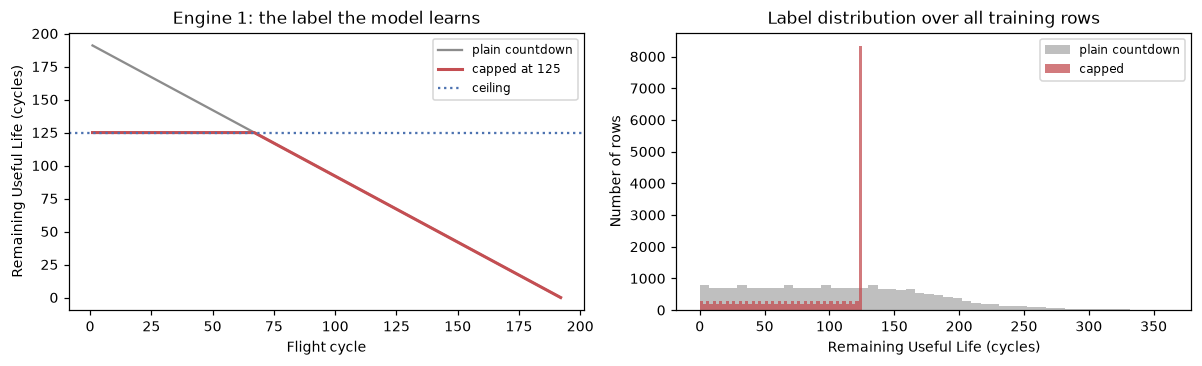

Capping affects 38.9% of training rows.
Capping affects 11.0% of test engines.


In [11]:
train_labeled = apply_piecewise_rul(data.train, rul_max=config.rul_max, output_column="rul_capped")
test_labeled = apply_piecewise_rul(data.test, rul_max=config.rul_max, output_column="rul_capped")

example_unit = int(train_labeled["unit"].iloc[0])
history = train_labeled[train_labeled["unit"] == example_unit]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))

axes[0].plot(history["cycle"], history["rul"], label="plain countdown", color="#8C8C8C")
axes[0].plot(history["cycle"], history["rul_capped"], label=f"capped at {config.rul_max}",
             color="#C44E52", linewidth=2)
axes[0].axhline(config.rul_max, color="#4C72B0", linestyle=":", label="ceiling")
axes[0].set_xlabel("Flight cycle")
axes[0].set_ylabel("Remaining Useful Life (cycles)")
axes[0].set_title(f"Engine {example_unit}: the label the model learns")
axes[0].legend(fontsize=8)

axes[1].hist(train_labeled["rul"], bins=50, alpha=0.55, label="plain countdown", color="#8C8C8C")
axes[1].hist(train_labeled["rul_capped"], bins=50, alpha=0.75, label="capped", color="#C44E52")
axes[1].set_xlabel("Remaining Useful Life (cycles)")
axes[1].set_ylabel("Number of rows")
axes[1].set_title("Label distribution over all training rows")
axes[1].legend(fontsize=8)

fig.tight_layout()
plt.show()

capped_share = (data.train["rul"] > config.rul_max).mean()
print(f"Capping affects {capped_share:.1%} of training rows.")
print(f"Capping affects {(data.test_rul > config.rul_max).mean():.1%} of test engines.")

The right-hand plot shows what the cap achieves. Without it the labels stretch across a wide range with a long, thin tail of high values that the sensors cannot distinguish. With it, that tail collapses into a single spike at the ceiling, and the model is asked only to make distinctions the data actually supports.

In [12]:
# Apply the cap in place from here on.
train_frame = apply_piecewise_rul(data.train, rul_max=config.rul_max)
test_frame = (
    apply_piecewise_rul(data.test, rul_max=config.rul_max)
    if config.clip_test_labels else data.test.copy()
)

assert train_frame["rul"].max() <= config.rul_max
assert train_frame["rul"].min() == 0
print(f"OK  Training labels now lie in [{train_frame['rul'].min()}, {train_frame['rul'].max()}].")
print(f"OK  Test labels now lie in [{test_frame['rul'].min()}, {test_frame['rul'].max()}].")

OK  Training labels now lie in [0, 125].
OK  Test labels now lie in [7, 125].


## 8. Step 5 — Smooth the signals

Sensor readings contain **measurement noise**: small, fast fluctuations unrelated to engine wear. Wear itself is slow and gradual. Removing the fast part makes the slow trend easier to see.

### The filter

An **exponentially weighted moving average** replaces each reading with a blend of that reading and the smoothed value from the previous cycle:

$$S_t = \alpha X_t + (1 - \alpha) S_{t-1}$$

- $\alpha$ close to 1: almost no smoothing, the output follows the raw signal.
- $\alpha$ close to 0: strong smoothing, but the output reacts late to a real change.

The name comes from expanding the formula: every past reading contributes, with a weight that shrinks exponentially the further back it lies.

### Two properties that keep the experiment honest

**It only looks backwards.** $S_t$ depends on $X_t$ and earlier values, never on later ones. A filter that averaged over future readings would leak information about the future into the present, and the model would appear to predict failure better than it really can. This is a form of **data leakage** (Kapoor & Narayanan, 2023) and is checked by an automated test.

**It is applied per engine.** No reading from one engine can influence another.

### The value of $\alpha$

**Assumption A-04.** Section 3.2.3 of the paper says: *"S(t-1) indicates the previous smoothed value, which is equal to 0.5 in this study; α constitutes the smoothing parameter"*. As written, 0.5 is attached to the wrong symbol. Since $S_{t-1}$ is a different quantity at every time step, it cannot be a fixed number; the only reading that makes the sentence meaningful is $\alpha = 0.5$.

12:29:26 | INFO    | thesis_gnn_rul_xai.data.smoothing | Applied exponentially weighted moving average (alpha=0.500) to 14 columns across 100 engines.


12:29:26 | INFO    | thesis_gnn_rul_xai.data.smoothing | Applied exponentially weighted moving average (alpha=0.500) to 14 columns across 100 engines.


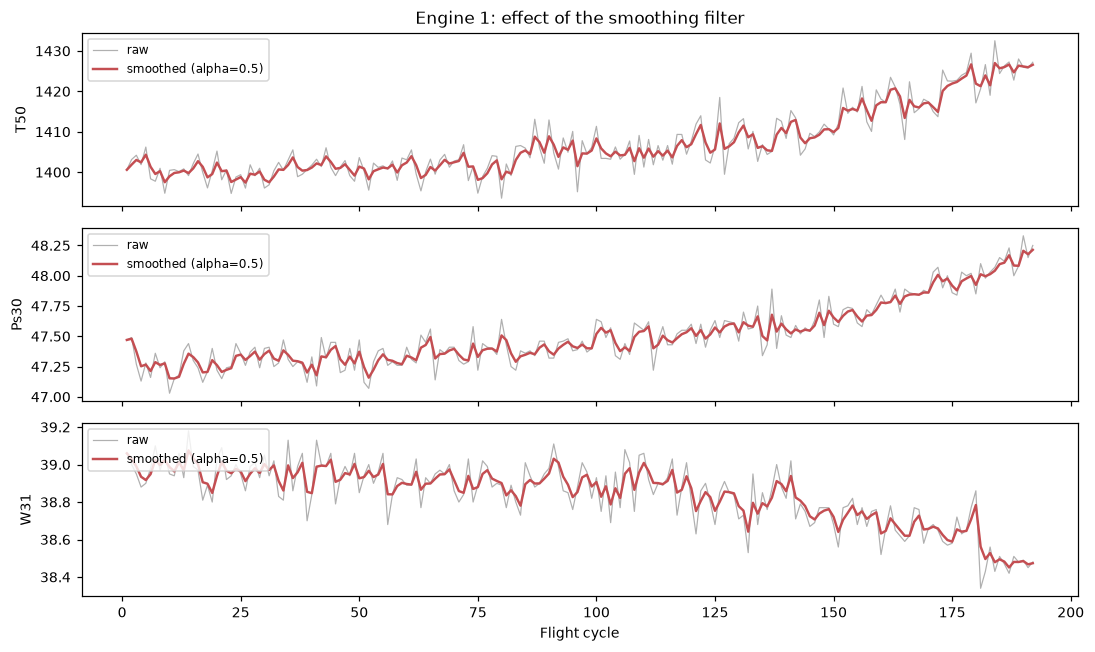

In [13]:
train_smoothed = apply_ewma(train_frame, sensor_columns, alpha=config.smoothing_alpha)
test_smoothed = apply_ewma(test_frame, sensor_columns, alpha=config.smoothing_alpha)

# Show the effect on the three sensors that degrade most clearly.
show_symbols = ["T50", "Ps30", "W31"]
fig, axes = plt.subplots(len(show_symbols), 1, figsize=(10, 6), sharex=True)

for axis, symbol in zip(axes, show_symbols):
    column = sensor_columns[list(PAPER_SENSOR_SYMBOLS).index(symbol)]
    raw = train_frame[train_frame["unit"] == example_unit]
    smooth = train_smoothed[train_smoothed["unit"] == example_unit]
    axis.plot(raw["cycle"], raw[column], color="#B0B0B0", linewidth=0.8, label="raw")
    axis.plot(smooth["cycle"], smooth[column], color="#C44E52", linewidth=1.6,
              label=f"smoothed (alpha={config.smoothing_alpha})")
    axis.set_ylabel(symbol)
    axis.legend(fontsize=8, loc="upper left")

axes[-1].set_xlabel("Flight cycle")
axes[0].set_title(f"Engine {example_unit}: effect of the smoothing filter")
fig.tight_layout()
plt.show()

In [14]:
# Quantify the effect: how much of the cycle-to-cycle jitter was removed?
def mean_absolute_step(frame: pd.DataFrame, column: str) -> float:
    """Average size of the change from one cycle to the next, over all engines."""
    return frame.groupby("unit")[column].diff().abs().mean()

rows = []
for symbol, column in zip(PAPER_SENSOR_SYMBOLS, sensor_columns):
    before = mean_absolute_step(train_frame, column)
    after = mean_absolute_step(train_smoothed, column)
    rows.append({
        "sensor": symbol,
        "jitter_before": before,
        "jitter_after": after,
        "reduction": 1 - after / before if before > 0 else 0.0,
    })
jitter = pd.DataFrame(rows)
display(jitter.style.format({"jitter_before": "{:.4f}", "jitter_after": "{:.4f}",
                             "reduction": "{:.1%}"}))
print(f"\nMedian reduction in cycle-to-cycle jitter: {jitter['reduction'].median():.1%}")

,sensor,jitter_before,jitter_after,reduction
0,T24,0.3410,0.1396,59.1%
1,T30,4.5060,1.8487,59.0%
2,T50,4.5572,1.8661,59.1%
3,P15,0.0004,0.0002,49.4%
4,P30,0.4594,0.1876,59.1%
5,Nf,0.0339,0.0140,58.7%
6,Nc,4.7047,1.9560,58.4%
7,Ps30,0.1146,0.0471,58.9%
8,phi,0.3398,0.1393,59.0%
9,NRf,0.0341,0.0141,58.7%



Median reduction in cycle-to-cycle jitter: 59.0%


## 9. Steps 6 and 7 — Hold out the validation engines, then rescale

Two steps happen in this section, and **the order between them matters**.

The 20 validation engines are chosen *first*, before any average, minimum
or maximum is computed. If the scaling were worked out over all 100
engines and 20 of them were held back afterwards, one of those held-back
engines could be the one defining a sensor's largest value, and the
held-back set would have quietly helped to prepare the data it is supposed
to judge. Section 11 explains what the split is for; here it is only
decided.

### Why rescaling is needed

The 14 sensors measure different physical quantities on wildly different scales: a turbine outlet temperature near 1400 degrees Rankine, a bypass ratio near 8.4, a coolant bleed flow near 39 pounds per second. Fed to a neural network unchanged, the large numbers dominate simply because they are large.

### What an operating condition is

The three "operational setting" columns describe how the aircraft was flown: altitude, Mach number, and throttle position. Flying higher or faster changes every sensor immediately and by a lot — and that change has nothing to do with wear.

In FD002 and FD004 the engines fly under six conditions, and the jumps between them are far larger than the slow drift caused by degradation. Scaling all six together buries the wear signal. Scaling each condition separately removes the flight-related jumps and leaves the wear visible.

**FD001 has only one operating condition**, so per-condition and global scaling give identical results here. The general version is implemented and tested now so that the code is already correct when FD002 and FD004 are added.

Conditions are found with **k-means clustering**, a standard algorithm that groups points into a chosen number of clusters by repeatedly assigning each point to the nearest cluster centre and recomputing the centres (MacQueen, 1967).

### The rule that protects the whole experiment

> **All statistics come from the training engines only.**

Every minimum, maximum, mean, standard deviation and cluster centre is computed on training data and then applied *unchanged* to the test data.

If the maximum were computed over training and test data together, information about the test engines would enter the training process. The model would then be evaluated on data it had partly seen, and the reported error would be smaller than the error the same model would produce on genuinely new engines. This is **data leakage**, and it is among the most common causes of published results that cannot be reproduced (Kapoor & Narayanan, 2023).

**Assumption A-03.** The paper never describes its input scaling at all — the words "normalisation", "min-max" and "standardisation" do not appear in connection with the inputs, and operating conditions are never mentioned in its preprocessing section. The procedure used here is taken from Jin et al. (2025), who study the same dataset with a comparable architecture and describe their steps explicitly. This is a documented *substitution*, not a reconstruction of what the original authors did.

In [15]:
# The validation engines are chosen HERE, before any statistic is learned.
# Fitting the encoder or the scaler on all 100 engines and only afterwards
# holding 20 of them out would let a held-out engine define a sensor's range,
# which is the same kind of leak that keeping the test set separate prevents.
train_units, validation_units = split_units_by_id(
    np.unique(train_smoothed["unit"].to_numpy()),
    validation_fraction=config.validation_fraction,
    seed=config.seed,
)
fitting_frame = train_smoothed[train_smoothed["unit"].isin(train_units)]
print(f"Statistics will be fitted on {len(train_units)} training engines; "
      f"{len(validation_units)} engines are held out.")

condition_encoder = OperatingConditionEncoder(seed=config.seed).fit(fitting_frame)
train_conditioned = condition_encoder.transform(train_smoothed)
test_conditioned = condition_encoder.transform(test_smoothed)

print(f"\nOperating conditions found in training data: {condition_encoder.n_detected}")
print("Rows per condition (training):")
print(train_conditioned[CONDITION_COL].value_counts().sort_index().to_string())
print("\nRows per condition (test):")
print(test_conditioned[CONDITION_COL].value_counts().sort_index().to_string())

12:29:26 | INFO    | thesis_gnn_rul_xai.data.windowing | Split 100 engines into 80 for training and 20 for validation (seed=42).


Statistics will be fitted on 80 training engines; 20 engines are held out.
12:29:26 | INFO    | thesis_gnn_rul_xai.data.normalization | Detected 1 distinct operating condition(s) from the settings.


12:29:26 | INFO    | thesis_gnn_rul_xai.data.normalization | A single operating condition: clustering is not needed.



Operating conditions found in training data: 1
Rows per condition (training):
operating_condition
0    20631

Rows per condition (test):
operating_condition
0    13096


In [16]:
normalizer = SensorNormalizer(method=config.normalization, columns=sensor_columns)
normalizer.fit(train_conditioned[train_conditioned["unit"].isin(train_units)])  # <-- training engines only

train_scaled = normalizer.transform(train_conditioned)
test_scaled = normalizer.transform(test_conditioned)

print("\nLearned scaling statistics (first five sensors):")
display(normalizer.statistics_.head(5).style.format(
    {"min": "{:.3f}", "max": "{:.3f}", "mean": "{:.3f}", "std": "{:.3f}"}))

12:29:26 | INFO    | thesis_gnn_rul_xai.data.normalization | Fitted 'minmax_per_condition' normalisation on 14 column(s) across 1 condition(s).



Learned scaling statistics (first five sensors):


,condition,column,min,max,mean,std,n_rows
0,0,sensor_2,641.450,644.243,642.675,0.430,16779
1,0,sensor_3,1573.020,1609.775,1590.449,5.119,16779
2,0,sensor_4,1386.367,1434.597,1408.823,8.262,16779
3,0,sensor_6,21.600,21.610,21.610,0.001,16779
4,0,sensor_7,550.750,555.385,553.379,0.814,16779


In [17]:
# The scale was learned from the 80 training engines only, so they are the
# only rows guaranteed to land inside [0, 1]. Reporting the three groups
# separately makes that visible.
def report_range(frame, label):
    values = frame[sensor_columns].to_numpy()
    print(f"{label:<34} [{values.min():+.4f}, {values.max():+.4f}]")

fitting_rows = train_scaled["unit"].isin(train_units)
report_range(train_scaled[fitting_rows], "Training engines (scale fitted here)")
report_range(train_scaled[~fitting_rows], "Validation engines (held out)")
report_range(test_scaled, "Test engines")

print()
print("The training engines span exactly [0, 1], because their own minimum and")
print("maximum define the scale. The validation and test engines may fall")
print("slightly outside, and that is correct: an engine that never contributed")
print("to the statistics can run a little hotter than anything seen while")
print("fitting them. Clipping those values would hide a real difference.")
print()
print("Before the fix recorded in docs/ASSUMPTIONS.md the scale was fitted on")
print("all 100 engines, so the validation engines were inside [0, 1] too - and")
print("that was the leak: a held-out engine was helping to set the scale.")

Training engines (scale fitted here) [+0.0000, +1.0000]
Validation engines (held out)      [-0.0118, +1.1279]
Test engines                       [-0.0789, +1.0183]

The training engines span exactly [0, 1], because their own minimum and
maximum define the scale. The validation and test engines may fall
slightly outside, and that is correct: an engine that never contributed
to the statistics can run a little hotter than anything seen while
fitting them. Clipping those values would hide a real difference.

Before the fix recorded in docs/ASSUMPTIONS.md the scale was fitted on
all 100 engines, so the validation engines were inside [0, 1] too - and
that was the leak: a held-out engine was helping to set the scale.


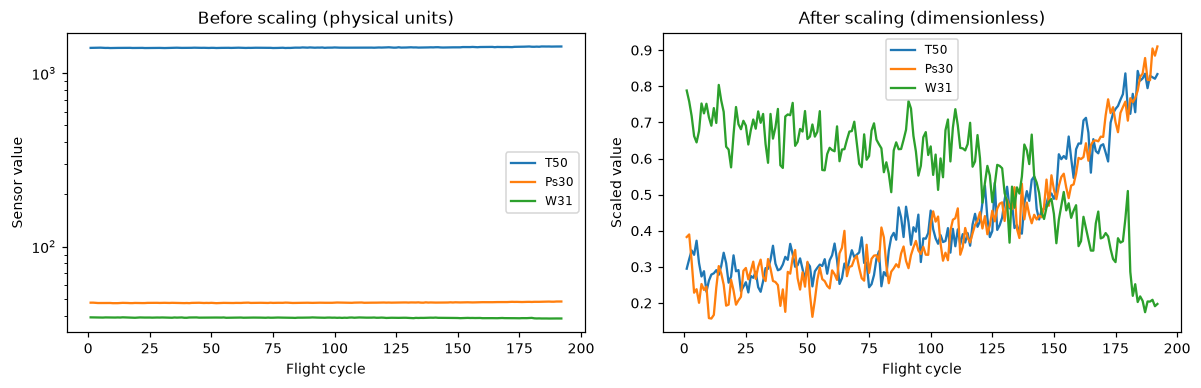

The left panel needs a logarithmic axis to show three sensors at once.
After scaling they are directly comparable, and the degradation trend is
visible in all three.


In [18]:
# Before and after, on a common axis, for the same three sensors.
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
history_raw = train_smoothed[train_smoothed["unit"] == example_unit]
history_scaled = train_scaled[train_scaled["unit"] == example_unit]

for symbol in show_symbols:
    column = sensor_columns[list(PAPER_SENSOR_SYMBOLS).index(symbol)]
    axes[0].plot(history_raw["cycle"], history_raw[column], label=symbol)
    axes[1].plot(history_scaled["cycle"], history_scaled[column], label=symbol)

axes[0].set_title("Before scaling (physical units)")
axes[0].set_xlabel("Flight cycle"); axes[0].set_ylabel("Sensor value")
axes[0].set_yscale("log"); axes[0].legend(fontsize=8)

axes[1].set_title("After scaling (dimensionless)")
axes[1].set_xlabel("Flight cycle"); axes[1].set_ylabel("Scaled value")
axes[1].legend(fontsize=8)

fig.tight_layout()
plt.show()
print("The left panel needs a logarithmic axis to show three sensors at once.")
print("After scaling they are directly comparable, and the degradation trend is")
print("visible in all three.")

### Demonstrating that no leakage happens

The claim above is worth testing rather than trusting. The next cell deliberately corrupts the test set by multiplying every sensor by one million, applies the fitted scaler to it, and then checks that the *training* data still scales to exactly the same numbers as before.

If the scaler were being refitted on whatever data it was shown, this check would fail.

In [19]:
before = normalizer.transform(train_conditioned)[sensor_columns].to_numpy()

corrupted = test_conditioned.copy()
corrupted[sensor_columns] = corrupted[sensor_columns] * 1_000_000
_ = normalizer.transform(corrupted)

after = normalizer.transform(train_conditioned)[sensor_columns].to_numpy()

assert np.array_equal(before, after), "LEAKAGE: the scaler changed after seeing test data."
print("OK  Corrupting the test set by a factor of one million changed nothing")
print("    about how the training data is scaled. No leakage through this step.")

OK  Corrupting the test set by a factor of one million changed nothing
    about how the training data is scaled. No leakage through this step.


## 10. Step 8 — Cut the histories into windows

A network needs a fixed-size input, but engine histories have different lengths. The histories are therefore cut into short, fixed-length pieces called **time windows**. One window is one example.

With a window of 30 cycles and a **stride** of 1, the first example covers cycles 1-30, the second covers 2-31, and so on.

Each window is labelled with the Remaining Useful Life at its **last** cycle. That matches how the model would be used: an operator has the most recent 30 cycles of readings and wants to know the remaining life *now*.

The paper gives a window of 30 in its Table 6 but no stride; 1 is used here (**assumption A-05**).

### The shape of the result

The array is arranged for a graph neural network, where each sensor is a node:

$$(\text{examples},\; \text{sensors},\; \text{features per sensor}) = (N,\; 14,\; 30)$$

**Assumption A-07.** The paper's Table 4 gives the input to the first graph layer as `[batch, 14, 1]` — one number per sensor, produced by a per-sensor LSTM whose size and depth are never stated. Because this project omits the LSTM stage (**assumption A-11**), each sensor node instead carries its whole 30-cycle window. Passing only the last reading with no temporal encoder would throw away 29 of the 30 cycles and make the window size meaningless.

### Test data is treated differently, for a reason

Test histories stop before failure, and the official label describes exactly one moment: the last recorded cycle. The evaluation therefore uses **one window per test engine**, its final one. On the real FD001 this gives 100 predictions, which matches the "number of testing samples" column in the paper's Table 5.

In [20]:
train_windows_all = make_windows(
    train_scaled, sensor_columns,
    window_size=config.window_size,
    stride=config.window_stride,
    node_feature_mode=config.node_feature_mode,
)
test_windows = make_last_windows(
    test_scaled, sensor_columns,
    window_size=config.window_size,
    node_feature_mode=config.node_feature_mode,
)

print()
print(f"Training windows : {train_windows_all}")
print(f"Test windows     : {test_windows}")
print()
print(f"Feature array shape: {train_windows_all.features.shape}")
print(f"  axis 0 = {train_windows_all.features.shape[0]:>6} examples")
print(f"  axis 1 = {train_windows_all.features.shape[1]:>6} sensors (graph nodes)")
print(f"  axis 2 = {train_windows_all.features.shape[2]:>6} cycles per sensor")
print(f"Memory: {train_windows_all.features.nbytes / 1024**2:.1f} MB as float32")

12:29:27 | INFO    | thesis_gnn_rul_xai.data.windowing | Built 17731 window(s) of shape (14, 30) from 100 engine(s).


12:29:27 | INFO    | thesis_gnn_rul_xai.data.windowing | Built 100 window(s) of shape (14, 30) from 100 engine(s).



Training windows : WindowedDataset(examples=17731, shape=(17731, 14, 30), engines=100, target_range=(0, 125))
Test windows     : WindowedDataset(examples=100, shape=(100, 14, 30), engines=100, target_range=(7, 125))

Feature array shape: (17731, 14, 30)
  axis 0 =  17731 examples
  axis 1 =     14 sensors (graph nodes)
  axis 2 =     30 cycles per sensor
Memory: 28.4 MB as float32


In [21]:
# Check: one test window per engine, and its label is the official one.
assert len(test_windows) == test_scaled["unit"].nunique()
print(f"OK  Exactly one window per test engine ({len(test_windows)} engines).")

official_capped = np.minimum(data.test_rul.sort_index().to_numpy(), config.rul_max)
order = np.argsort(test_windows.units)
assert np.allclose(test_windows.targets[order], official_capped)
print("OK  Every test window carries the official (capped) label.")

OK  Exactly one window per test engine (100 engines).
OK  Every test window carries the official (capped) label.


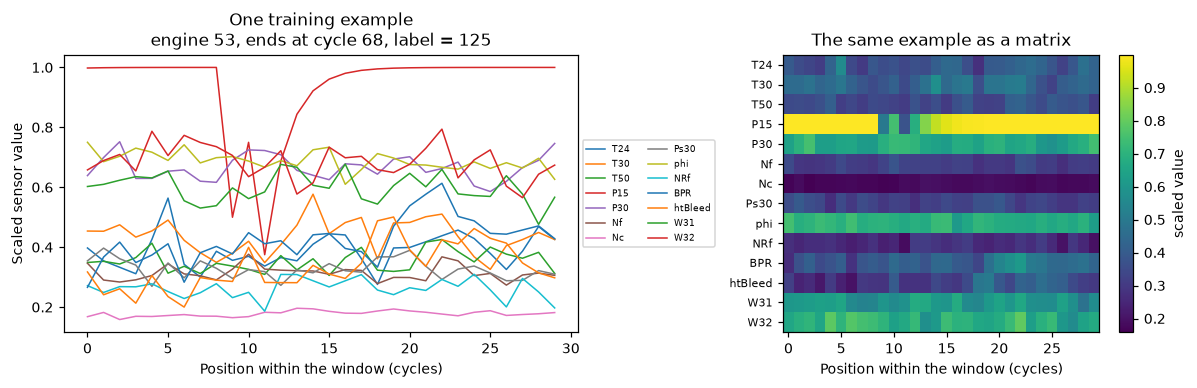

In [22]:
# What one example actually looks like: 14 sensor traces, 30 cycles each.
example_index = len(train_windows_all) // 2
example = train_windows_all.features[example_index]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6),
                         gridspec_kw={"width_ratios": [1.3, 1]})

for node_index, symbol in enumerate(PAPER_SENSOR_SYMBOLS):
    axes[0].plot(range(config.window_size), example[node_index], linewidth=1, label=symbol)
axes[0].set_xlabel("Position within the window (cycles)")
axes[0].set_ylabel("Scaled sensor value")
axes[0].set_title(
    f"One training example\n"
    f"engine {train_windows_all.units[example_index]}, "
    f"ends at cycle {train_windows_all.end_cycles[example_index]}, "
    f"label = {train_windows_all.targets[example_index]:.0f}"
)
axes[0].legend(fontsize=6, ncol=2, loc="center left", bbox_to_anchor=(1.0, 0.5))

image = axes[1].imshow(example, aspect="auto", cmap="viridis")
axes[1].set_yticks(range(14))
axes[1].set_yticklabels(PAPER_SENSOR_SYMBOLS, fontsize=7)
axes[1].set_xlabel("Position within the window (cycles)")
axes[1].set_title("The same example as a matrix")
fig.colorbar(image, ax=axes[1], label="scaled value")

fig.tight_layout()
plt.show()

## 11. Applying the split from step 6

Step 6 chose *which* engines to hold back, in section 9. Now that the
histories have been cut into windows, that decision is applied: every
window inherits the side its engine was assigned to.

A **validation set** is a portion of the training data that is held back and never used to update the model. It is used to decide when to stop training and to compare settings, so that those decisions are not made by looking at the test set.

### The split must be by engine, not by window

This is easy to get wrong and expensive when you do. With a window of 30 and a stride of 1, two neighbouring windows from the same engine share **29 of their 30 cycles**, and their labels differ by one. If windows were split at random, nearly identical examples would land on both sides, and the validation error would be far too optimistic — the model would effectively be tested on data it had already trained on.

Splitting whole engines keeps the two sets genuinely separate.

**Assumption A-06.** The paper describes no validation split at all; its Table 6 states a fixed 200 epochs with no early stopping. Adding one here is a deliberate improvement on the source and should be described that way in the thesis.

In [23]:
# The engines were split in section 9, before any statistic was fitted.
# Here that decision is simply applied to the windows.
train_windows = train_windows_all.subset_by_units(train_units)
validation_windows = train_windows_all.subset_by_units(validation_units)

print()
print(f"Training   : {len(train_windows):>6} windows from {len(train_units)} engines")
print(f"Validation : {len(validation_windows):>6} windows from {len(validation_units)} engines")
print(f"Test       : {len(test_windows):>6} windows from {len(np.unique(test_windows.units))} engines")

overlap = set(train_windows.units.tolist()) & set(validation_windows.units.tolist())
assert not overlap, f"Engines in both splits: {sorted(overlap)}"
print("\nOK  No engine appears in both splits.")
print(f"OK  All windows accounted for: "
      f"{len(train_windows)} + {len(validation_windows)} = {len(train_windows_all)}")


Training   :  14459 windows from 80 engines
Validation :   3272 windows from 20 engines
Test       :    100 windows from 100 engines

OK  No engine appears in both splits.
OK  All windows accounted for: 14459 + 3272 = 17731


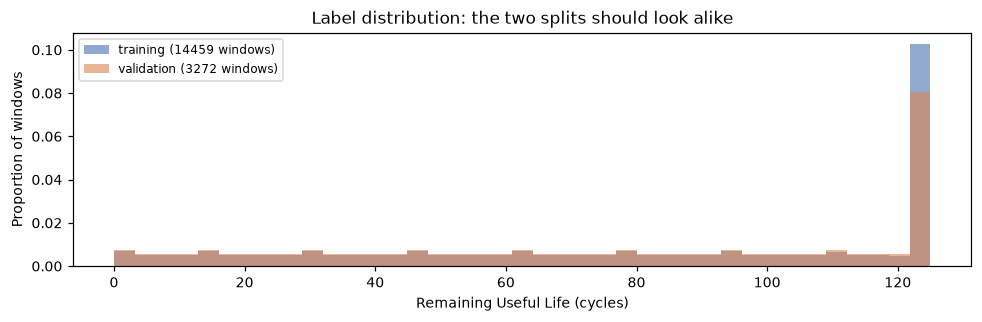

Mean label, training   :  81.48 cycles
Mean label, validation :  76.91 cycles
Difference             :   4.57 cycles


In [24]:
# The label distributions of the two splits should look similar. A large
# difference would mean the split happened to separate short-lived engines
# from long-lived ones, which would bias the validation estimate.
fig, axis = plt.subplots(figsize=(9, 3))
bins = np.linspace(0, config.rul_max, 40)
axis.hist(train_windows.targets, bins=bins, alpha=0.6, density=True,
          label=f"training ({len(train_windows)} windows)", color="#4C72B0")
axis.hist(validation_windows.targets, bins=bins, alpha=0.6, density=True,
          label=f"validation ({len(validation_windows)} windows)", color="#DD8452")
axis.set_xlabel("Remaining Useful Life (cycles)")
axis.set_ylabel("Proportion of windows")
axis.set_title("Label distribution: the two splits should look alike")
axis.legend(fontsize=8)
fig.tight_layout()
plt.show()

print(f"Mean label, training   : {train_windows.targets.mean():6.2f} cycles")
print(f"Mean label, validation : {validation_windows.targets.mean():6.2f} cycles")
print(f"Difference             : "
      f"{abs(train_windows.targets.mean() - validation_windows.targets.mean()):6.2f} cycles")

## 12. The sensor graph

This is the part of the paper that is **fully specified**. Its Table 3 prints the entire 14-by-14 adjacency matrix, so nothing has to be assumed here — only transcribed correctly, which is checked automatically.

### How the authors built it

Most work on this dataset builds the graph from the data, connecting sensors whose readings correlate. Wen et al. instead designed theirs by hand from knowledge of how a turbofan works. Their five rules:

1. **Same location.** Sensors at the same engine station are connected, because they measure the same gas at the same point. Example: `P30` and `Ps30`, the total and static pressure at the high-pressure compressor outlet.
2. **Speed correction.** A raw speed is connected to its corrected counterpart, because one is computed from the other. Example: `Nf` and `NRf`.
3. **Gas path.** Sensors are connected along the route the gas actually takes. Example: the temperature chain `T24` → `T30` → `T50`, following the flow from low-pressure compressor to high-pressure compressor to low-pressure turbine.
4. **Fuel and control.** Fuel quantities are connected to what they influence. Example: `phi`, the ratio of fuel flow to static pressure, is connected to the temperatures and pressures that burning more fuel changes.
5. **Cooling.** The coolant bleeds are connected to each other, because they jointly manage turbine temperature.

### Why it must be normalised before use

A graph convolution layer does not use the raw matrix $A$. It uses (Kipf & Welling, 2017):

$$\hat{A} = D^{-1/2}\,(A + I)\,D^{-1/2}$$

Two things happen here:

- Adding the identity matrix $I$ puts a **self-loop** on every node. Without it a node would be updated only from its neighbours and would forget its own current value.
- Dividing by the square roots of the **degrees** (the number of edges at each node, held on the diagonal of $D$) stops well-connected nodes from dominating. Without this, repeatedly summing over neighbours makes values grow layer after layer and training becomes unstable.

In [25]:
adjacency, symbols = build_physics_adjacency()
report = adjacency_report(adjacency, symbols)

print("Properties of the sensor graph")
print("-" * 50)
for key in ["n_nodes", "n_edges", "density", "is_symmetric", "has_self_loops", "is_connected"]:
    value = report[key]
    print(f"  {key:16s} {value:.4f}" if isinstance(value, float) else f"  {key:16s} {value}")

print("\nDegree of each sensor (how many neighbours it has):")
degrees = pd.Series(report["degrees"]).sort_values(ascending=False)
print(degrees.to_string())

assert report["is_symmetric"], "Transcription error: the matrix is not symmetric."
assert report["is_connected"], "The graph is not connected."
assert report["n_edges"] == 41, "Edge count differs from the published table."
print("\nOK  Symmetric, connected, 41 undirected edges - matches the paper's Table 3.")

Properties of the sensor graph
--------------------------------------------------
  n_nodes          14
  n_edges          41
  density          0.4505
  is_symmetric     True
  has_self_loops   False
  is_connected     True

Degree of each sensor (how many neighbours it has):
T30        8
Nc         8
W31        8
htBleed    7
P30        7
T24        7
Ps30       7
phi        6
T50        4
P15        4
Nf         4
NRf        4
BPR        4
W32        4

OK  Symmetric, connected, 41 undirected edges - matches the paper's Table 3.


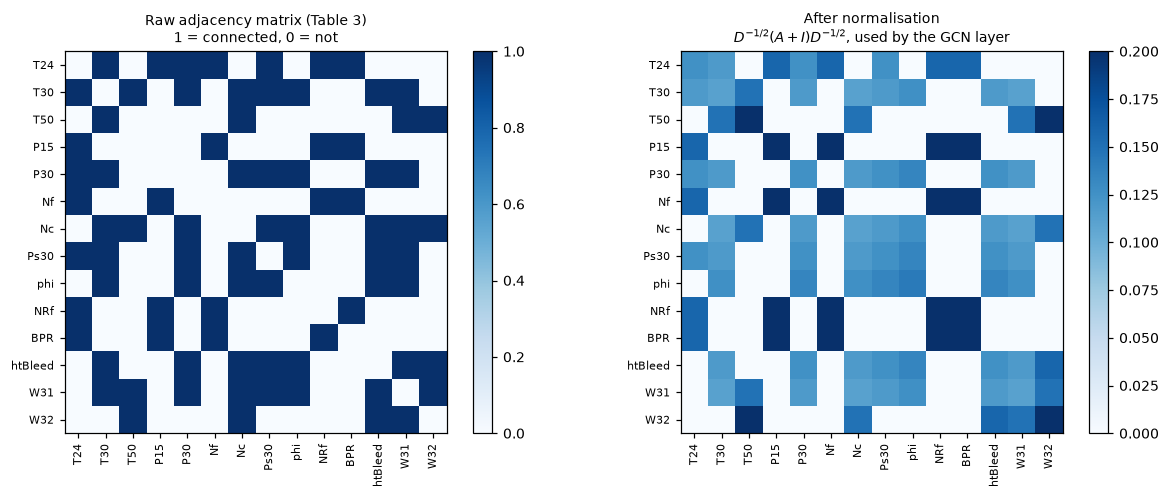

Notice the diagonal in the right-hand panel: it is empty on the left
(Table 3 has no self-loops) and filled on the right (the formula adds them).


In [26]:
normalized_adjacency = normalize_adjacency(adjacency)

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.6))

for axis, matrix, title in [
    (axes[0], adjacency, "Raw adjacency matrix (Table 3)\n1 = connected, 0 = not"),
    (axes[1], normalized_adjacency,
     "After normalisation\n$D^{-1/2}(A+I)D^{-1/2}$, used by the GCN layer"),
]:
    image = axis.imshow(matrix, cmap="Blues", vmin=0)
    axis.set_xticks(range(14)); axis.set_xticklabels(symbols, rotation=90, fontsize=7)
    axis.set_yticks(range(14)); axis.set_yticklabels(symbols, fontsize=7)
    axis.set_title(title, fontsize=9)
    fig.colorbar(image, ax=axis, fraction=0.046)

fig.tight_layout()
plt.show()

print("Notice the diagonal in the right-hand panel: it is empty on the left")
print("(Table 3 has no self-loops) and filled on the right (the formula adds them).")

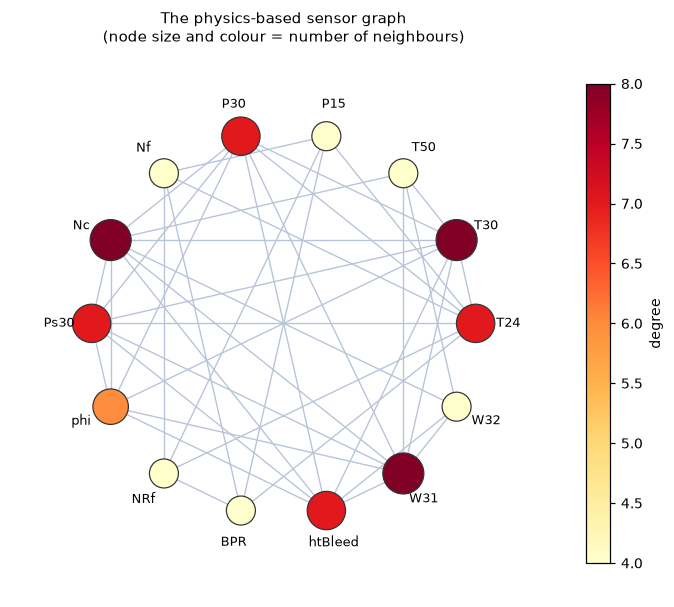

In [27]:
# The graph drawn as a network, with node size showing degree.
angles = np.linspace(0, 2 * np.pi, 14, endpoint=False)
positions = np.column_stack([np.cos(angles), np.sin(angles)])

fig, axis = plt.subplots(figsize=(6.2, 6.2))
for i in range(14):
    for j in range(i + 1, 14):
        if adjacency[i, j]:
            axis.plot(*zip(positions[i], positions[j]), color="#B8C4D9", linewidth=0.9, zorder=1)

degree_values = adjacency.sum(axis=1)
scatter = axis.scatter(positions[:, 0], positions[:, 1], s=degree_values * 90,
                       c=degree_values, cmap="YlOrRd", edgecolors="#333333",
                       linewidths=0.8, zorder=2)
for position, symbol in zip(positions, symbols):
    axis.annotate(symbol, position * 1.17, ha="center", va="center", fontsize=8.5)

axis.set_xlim(-1.42, 1.42); axis.set_ylim(-1.42, 1.42)
axis.set_aspect("equal"); axis.axis("off")
axis.set_title("The physics-based sensor graph\n(node size and colour = number of neighbours)",
               fontsize=10)
fig.colorbar(scatter, ax=axis, label="degree", fraction=0.04)
fig.tight_layout()
plt.show()

### The hand-designed graph compared with a data-driven one

Most published methods on this dataset connect sensors whose readings **correlate**. The **Pearson correlation coefficient** measures how closely two quantities follow a straight-line relationship: it runs from $-1$ (one rises exactly as the other falls), through $0$ (no straight-line relationship), to $+1$ (they rise and fall together).

Comparing the two graphs is useful for the thesis: it shows what the engineering knowledge adds, or fails to add, over what the data alone would suggest. It is also the natural comparison for the paper's own ablation, which it calls "without physics prior".

In [28]:
correlation_adjacency, _ = build_correlation_adjacency(
    train_scaled, sensor_columns, threshold=0.6
)
correlation_report = adjacency_report(correlation_adjacency, symbols)

agree_connected = int(((adjacency == 1) & (correlation_adjacency == 1)).sum() // 2)
only_physics = int(((adjacency == 1) & (correlation_adjacency == 0)).sum() // 2)
only_correlation = int(((adjacency == 0) & (correlation_adjacency == 1)).sum() // 2)

print(f"Physics graph      : {report['n_edges']} edges, density {report['density']:.3f}")
print(f"Correlation graph  : {correlation_report['n_edges']} edges, "
      f"density {correlation_report['density']:.3f}  (threshold 0.6)")
print()
print(f"  Edges in both              : {agree_connected}")
print(f"  Only in the physics graph  : {only_physics}")
print(f"  Only in the correlation graph : {only_correlation}")
print()
print("Edges present only in the physics graph are the interesting ones: they are")
print("relationships an engineer asserts but the data does not obviously show.")


12:29:28 | INFO    | thesis_gnn_rul_xai.graph.adjacency | Built a correlation graph with threshold 0.60: 66 undirected edge(s).


Physics graph      : 41 edges, density 0.451
Correlation graph  : 66 edges, density 0.725  (threshold 0.6)

  Edges in both              : 29
  Only in the physics graph  : 12
  Only in the correlation graph : 37

Edges present only in the physics graph are the interesting ones: they are
relationships an engineer asserts but the data does not obviously show.


## 13. The whole thing in one call

Every step above is also available as a single function. This is what a script or an automated test uses, and it is what guarantees the notebook and the rest of the project do exactly the same thing.

The next cell runs it and checks that the result is identical to what was built step by step. If those two ever disagree, the notebook and the package have drifted apart and one of them is wrong.

In [29]:
prepared = run_preprocessing(config, data_dir=data_dir, keep_frames=False)
print()
display(prepared.summary())

12:29:28 | INFO    | thesis_gnn_rul_xai.data.loading | Loading FD001 from D:\Main\University\Thesis\Code\Thesis GNN RUL XAI\data\raw


12:29:28 | INFO    | thesis_gnn_rul_xai.data.loading | FD001 matches the published shape of the official release.


12:29:28 | INFO    | thesis_gnn_rul_xai.data.loading | Loaded FD001: 20631 training rows over 100 engines, 13096 test rows over 100 engines.


12:29:28 | WARNING | thesis_gnn_rul_xai.data.pipeline | The paper keeps sensor(s) ['P15'], but in this data they carry no usable variation. They are kept anyway, because the adjacency matrix is defined over the paper's fixed 14-sensor set. Report this observation rather than silently changing the selection.


12:29:28 | INFO    | thesis_gnn_rul_xai.data.smoothing | Applied exponentially weighted moving average (alpha=0.500) to 14 columns across 100 engines.


12:29:28 | INFO    | thesis_gnn_rul_xai.data.smoothing | Applied exponentially weighted moving average (alpha=0.500) to 14 columns across 100 engines.


... (4 outputs left out)

12:29:28 | INFO    | thesis_gnn_rul_xai.data.windowing | Built 17731 window(s) of shape (14, 30) from 100 engine(s).


12:29:28 | INFO    | thesis_gnn_rul_xai.data.windowing | Built 100 window(s) of shape (14, 30) from 100 engine(s).


12:29:28 | INFO    | thesis_gnn_rul_xai.data.pipeline | Preprocessing complete: 14459 training, 3272 validation, 100 test example(s).


,examples,engines,feature_shape,target_min,target_max
split,,,,,
train,14459,80,"(14, 30)",0.0,125.0
validation,3272,20,"(14, 30)",0.0,125.0
test,100,100,"(14, 30)",7.0,125.0


In [30]:
np.testing.assert_array_equal(prepared.train.features, train_windows.features)
np.testing.assert_array_equal(prepared.train.targets, train_windows.targets)
np.testing.assert_array_equal(prepared.test.features, test_windows.features)
np.testing.assert_array_equal(prepared.validation.units, validation_windows.units)
print("OK  The one-call pipeline reproduces the step-by-step result exactly.")

OK  The one-call pipeline reproduces the step-by-step result exactly.


## 14. Final verification

Every claim this notebook makes, checked in one place. A reader who trusts nothing else should be able to run this cell.

In [31]:
checks: list[tuple[str, bool, str]] = []

def check(description: str, condition: bool, detail: str = "") -> None:
    checks.append((description, bool(condition), detail))

# --- shapes and alignment ---
n_nodes = prepared.adjacency_raw.shape[0]
check("Feature axis matches the graph size",
      prepared.train.features.shape[1] == n_nodes, f"{prepared.train.features.shape[1]} nodes")
check("Sensor order matches the paper's Table 3",
      list(prepared.sensor_symbols) == list(PAPER_SENSOR_SYMBOLS))
check("Window length matches the configuration",
      prepared.train.features.shape[2] == config.window_size, f"{config.window_size} cycles")

# --- labels ---
for name, dataset in [("training", prepared.train), ("validation", prepared.validation),
                      ("test", prepared.test)]:
    check(f"Labels within [0, {config.rul_max}] ({name})",
          dataset.targets.min() >= 0 and dataset.targets.max() <= config.rul_max,
          f"[{dataset.targets.min():.0f}, {dataset.targets.max():.0f}]")

# --- data hygiene ---
check("No missing or infinite feature values",
      all(np.isfinite(d.features).all()
          for d in (prepared.train, prepared.validation, prepared.test)))
check("Training and validation engines are disjoint",
      set(prepared.train.units.tolist()).isdisjoint(prepared.validation.units.tolist()))
check("Exactly one window per test engine",
      len(prepared.test) == len(np.unique(prepared.test.units)), f"{len(prepared.test)} engines")

# --- the graph ---
graph = prepared.diagnostics["graph"]
check("Graph is symmetric", graph["is_symmetric"])
check("Graph is connected", graph["is_connected"])
check("Graph has 41 edges, as published", graph["n_edges"] == 41, f"{graph['n_edges']} edges")
check("No isolated sensors", not graph["isolated_nodes"])
check("Normalised graph has self-loops",
      bool(np.all(np.diag(prepared.adjacency_normalized) > 0)))

# --- report ---
width = max(len(description) for description, _, _ in checks) + 2
print(f"{'CHECK':<{width}} RESULT   DETAIL")
print("-" * (width + 26))
for description, passed, detail in checks:
    print(f"{description:<{width}} {'PASS' if passed else 'FAIL':<8} {detail}")

failed = [description for description, passed, _ in checks if not passed]
print("-" * (width + 26))
if failed:
    raise AssertionError(f"{len(failed)} check(s) failed: {failed}")
print(f"All {len(checks)} checks passed.")

CHECK                                          RESULT   DETAIL
------------------------------------------------------------------------
Feature axis matches the graph size            PASS     14 nodes
Sensor order matches the paper's Table 3       PASS     
Window length matches the configuration        PASS     30 cycles
Labels within [0, 125] (training)              PASS     [0, 125]
Labels within [0, 125] (validation)            PASS     [0, 125]
Labels within [0, 125] (test)                  PASS     [7, 125]
No missing or infinite feature values          PASS     
Training and validation engines are disjoint   PASS     
Exactly one window per test engine             PASS     100 engines
Graph is symmetric                             PASS     
Graph is connected                             PASS     
Graph has 41 edges, as published               PASS     41 edges
No isolated sensors                            PASS     
Normalised graph has self-loops                PASS     
------

## 15. Save the result

Five files are written, so the modelling stage never has to repeat this work and so the exact inputs of any experiment can be recovered later:

| File | Contents |
|---|---|
| `windows.npz` | The three splits as arrays |
| `adjacency.npz` | The sensor graph, raw and normalised |
| `normalization_statistics.csv` | The learned scaling values |
| `config.yaml` | The exact settings used |
| `diagnostics.json` | What the pipeline observed |

Saving the settings alongside the arrays is what makes a result traceable. Six months from now, `config.yaml` is what answers the question "which version of the preprocessing produced this?"

In [32]:
output_dir = PROJECT_ROOT / "data" / "processed"
saved_to = prepared.save(output_dir)

print(f"\nSaved to: {saved_to}\n")
for path in sorted(saved_to.iterdir()):
    print(f"  {path.name:32s} {path.stat().st_size / 1024:8.1f} KB")

12:29:29 | INFO    | thesis_gnn_rul_xai.data.pipeline | Saved prepared data to D:\Main\University\Thesis\Code\Thesis GNN RUL XAI\data\processed



Saved to: D:\Main\University\Thesis\Code\Thesis GNN RUL XAI\data\processed

  adjacency.npz                         0.9 KB
  config.yaml                           0.4 KB
  diagnostics.json                      2.3 KB
  normalization_statistics.csv          1.2 KB
  windows.npz                        1579.0 KB


In [33]:
# Confirm the saved arrays can be read back and are identical.
with np.load(saved_to / "windows.npz", allow_pickle=False) as archive:
    print("Arrays in windows.npz:")
    for key in sorted(archive.files):
        print(f"  {key:20s} {archive[key].shape!s:>18}  {archive[key].dtype}")
    np.testing.assert_array_equal(archive["train_features"], prepared.train.features)

print("\nOK  Saved arrays match what is in memory.")

Arrays in windows.npz:
  sensor_columns                    (14,)  <U9
  test_end_cycles                  (100,)  int64
  test_features             (100, 14, 30)  float32
  test_targets                     (100,)  float32
  test_units                       (100,)  int64
  train_end_cycles               (14459,)  int64
  train_features          (14459, 14, 30)  float32
  train_targets                  (14459,)  float32
  train_units                    (14459,)  int64
  val_end_cycles                  (3272,)  int64
  val_features             (3272, 14, 30)  float32
  val_targets                     (3272,)  float32
  val_units                       (3272,)  int64

OK  Saved arrays match what is in memory.


## 16. Summary and next steps

### What this notebook produced

Starting from three plain text files, it produced:

- **Training, validation and test examples** of shape `(N, 14, 30)`: 14 sensor nodes, each carrying 30 cycles of scaled, smoothed readings.
- **A 14-node sensor graph**, transcribed from the paper's Table 3 and verified symmetric, connected, and with 41 edges.
- **A record of every decision**, including the eleven that the paper does not specify.

### Decisions that were not read from the paper

| ID | Decision | Value used |
|---|---|---|
| A-01 | Label ceiling | 125 cycles |
| A-02 | Ceiling applied to test labels | Yes |
| A-03 | Input rescaling | Per-condition min-max, from Jin et al. (2025) |
| A-04 | Smoothing strength | 0.5 |
| A-05 | Window stride | 1 cycle |
| A-06 | Validation split | 20 % of engines |
| A-07 | Node feature content | The whole 30-cycle window |
| A-08 | Order of smoothing and scaling | Smooth first |
| A-09 | Smoothing formula variant | Recursive form |
| A-10 | Seventh dropped sensor | `NRc` |
| A-11 | LSTM stage | Omitted |

Full justifications are in `docs/ASSUMPTIONS.md`. **A-11 is the one to keep in mind**: because the LSTM stage is omitted, results from this project must be compared against the paper's own **"ESTGNN w/o LSTM"** ablation row, not against its headline figures.

### What comes next

1. **Run this notebook on the real FD001 files** and compare the sensor diagnosis in section 5 with the paper's stated selection.
2. **Build the model**: three graph convolution layers of sizes 32, 64 and 32, then two fully connected layers, as in the paper's Table 4.
3. **Reproduce a simple published baseline first.** Li et al. (2018) report an error of about 12.6 on FD001. A pipeline that cannot approach a known baseline has a problem that no model tuning will fix — this is the single most useful check available at this stage.
4. **Add the evaluation measures**: the NASA scoring function, root mean squared error, the coefficient of determination, and average safe underestimation error.
5. **Add explanation methods**, starting with SHAP as the paper uses it, then moving to graph-native explanations that describe edges and subgraphs rather than individual sensors — the research gap this thesis addresses.

### References

- Corso, G., et al. (2024). Graph neural networks. *Nature Reviews Methods Primers*, 4, 17.
- Heimes, F. O. (2008). Recurrent neural networks for remaining useful life estimation. *PHM 2008*.
- Jin, Y., et al. (2025). Heterogeneous dynamic-aware GNN for RUL prediction of aeroengine. *IEEE TIM*, 74.
- Kapoor, S., & Narayanan, A. (2023). Leakage and the reproducibility crisis. *Patterns*, 4(9), 100804.
- Kipf, T. N., & Welling, M. (2017). Semi-supervised classification with graph convolutional networks. *ICLR*.
- Li, X., Ding, Q., & Sun, J.-Q. (2018). Remaining useful life estimation using deep convolution neural networks. *RESS*, 172, 1-11.
- Lundberg, S. M., & Lee, S.-I. (2017). A unified approach to interpreting model predictions. *NeurIPS 30*.
- MacQueen, J. (1967). Some methods for classification and analysis of multivariate observations. *Berkeley Symposium*.
- Saxena, A., et al. (2008). Damage propagation modeling for aircraft engine run-to-failure simulation. *PHM 2008*.
- Shapley, L. S. (1953). A value for n-person games. *Contributions to the Theory of Games II*.
- Wen, J.-R., et al. (2026). Explainable spatiotemporal graph neutral network with dynamic SHAP enhancement. *Aerospace Science and Technology*, 168, 110875.

Full citations, with a note on what each is used for, are in `docs/REFERENCES.md`.